In [ ]:
import re, os, io, unicodedata, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.ticker import PercentFormatter

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid", context="notebook", font_scale=1.05)
plt.rcParams.update({
    "figure.dpi": 120,
    "savefig.dpi": 220,
    "axes.titleweight": "bold",
    "axes.titlesize": 13,
    "axes.labelsize": 11,
    "figure.facecolor": "white",
})

In [ ]:
  #1. Carga
try:
    from google.colab import files
    print("Selecciona el archivo Excel de reacciones:")
    up = files.upload()
    df = pd.read_excel(io.BytesIO(list(up.values())[0]))
    EN_COLAB = True
except ImportError:
    df = pd.read_excel("TABLA REACCIONES PROYECTO DE QUIMICA.xlsx")
    EN_COLAB = False

df.columns = [c.strip() for c in df.columns]
os.makedirs("figuras", exist_ok=True)
# Paleta de medios (consistente en todas las figuras)
PAL_MEDIO = {
    "Ácido": "#c0392b",
    "Básico": "#2980b9",
    "Neutro": "#27ae60",
    "Apolar": "#e67e22",
    "No especificado": "#95a5a6",
}

def guardar(nombre):
    plt.tight_layout()
    plt.savefig(f"figuras/{nombre}.png", dpi=220, bbox_inches="tight", facecolor="white")
    plt.show()


Selecciona el archivo Excel de reacciones:


Saving TABLA REACCIONES PROYECTO DE QUIMICA.xlsx to TABLA REACCIONES PROYECTO DE QUIMICA.xlsx


In [ ]:
#2. Limpieza robusta
def sin_tildes(s):
    return "".join(c for c in unicodedata.normalize("NFD", str(s)) if unicodedata.category(c) != "Mn")

SUP = str.maketrans("⁰¹²³⁴⁵⁶⁷⁸⁹⁻", "0123456789-")

def a_num(x):
    """Convierte textos raros de SciFinder / Excel a float."""
    if pd.isna(x):
        return np.nan
    s = str(x).replace("\u200b", "").strip().translate(SUP)
    if s.lower() in ("rt", "ta", "r.t.", "room temp", "temperatura ambiente"):
        return 25.0
    s = re.sub(r"\s+", "", s)
    # notación científica tipo 1,20x10⁵ o 1.20e5
    m = re.match(r"^(-?[\d.,]+)[x×]10([+-]?\d+)$", s, flags=re.I)
    if m:
        return float(m.group(1).replace(",", ".")) * 10 ** int(m.group(2))
    m = re.match(r"^(-?[\d.,]+)[eE]([+-]?\d+)$", s)
    if m:
        return float(m.group(1).replace(",", ".")) * 10 ** int(m.group(2))
    try:
        return float(s.replace(",", "."))
    except ValueError:
        return np.nan

def reescala(v, lo, hi):
    if pd.isna(v):
        return v
    k = 0
    while v > hi and k < 5:
        v /= 10
        k += 1
    return v if lo <= v <= hi else np.nan

# Mapear columnas reales del Excel
COL = {
    "PM_S": "PM (g/mol)",
    "Tf_S": "PF(°C)",
    "Teb_S": "PE (°C)",
    "Dens_S": "D (g/cm³)",
    "pKa_S": "pKa",
    "Dip_S": "MD (D)",
    "Sol_S": "SA (g/L)",
    "Pv_S": "PvT: 298 K (Pa)",
    "PM_P": "Pm (g/mol)2",
    "Tf_P": "Pf(°C)2",
    "Teb_P": "Pe (°C)2",
    "Dens_P": "D (g/cm³)  2",
    "pKa_P": "pKa 2",
    "Dip_P": "Md (D)2",
    "Sol_P": "Sa (g/L) 2",
    "Pv_P": "Pvt: 298 K (Pa) 2",
    "Tr": "Tr (°C)",
    "tmin": "Condicion 1(min)",
    "Medio": "Medio",
    "Tipo": "Tpr",
    "Solvente": "Disolvente",
    "Sustrato": "Sustrato",
    "Producto": "Producto",
    "CAS_S": "NUMERO CAS SUSTRATO",
    "CAS_P": "NUMERO CAS PRODUCTO",
}

# Limpiar nombres de columnas que tienen espacios raros
def encontrar(prefijo):
    for c in df.columns:
        if sin_tildes(c).lower().startswith(sin_tildes(prefijo).lower()[:8]):
            return c
    return None

# Asignar columnas de forma tolerante
for k, v in list(COL.items()):
    if v not in df.columns:
        alt = encontrar(v)
        if alt:
            COL[k] = alt

# Convertir propiedades numéricas
for lado, suf in (("S", "_S"), ("P", "_P")):
    for sig, rng in {
        "PM": (5, 2000), "Tf": (-300, 600), "Teb": (-200, 900),
        "Dens": (0.2, 6), "pKa": (-15, 50), "Dip": (0, 20),
        "Sol": (0, 2e4), "Pv": (0, 1e9)
    }.items():
        col = COL.get(f"{sig}_{lado}")
        if col and col in df.columns:
            serie = df[col].map(a_num)
            if sig in ("PM", "Tf", "Teb", "Dens", "pKa", "Dip"):
                serie = serie.map(lambda z: reescala(z, *rng))
            df[f"{sig}{suf}"] = serie

df["T_rx"] = df[COL["Tr"]].map(a_num) if COL["Tr"] in df.columns else np.nan
df["t_min"] = df[COL["tmin"]].map(a_num) if COL["tmin"] in df.columns else np.nan
df["dPM"] = df["PM_P"] - df["PM_S"]

# Normalizar Medio
def norm_medio(x):
    t = sin_tildes(str(x)).lower()
    if "acid" in t: return "Ácido"
    if "basic" in t: return "Básico"
    if "neutr" in t: return "Neutro"
    if "apolar" in t or "no polar" in t: return "Apolar"
    return "No especificado"

df["Medio_n"] = df[COL["Medio"]].map(norm_medio)

# Normalizar Tipo de reacción (columna Tpr) -> SOLO los 9 tipos permitidos
TIPOS_9 = ["Adición nucleofílica", "Adición electrofílica", "Adición radicalaria",
           "Sustitución nucleofílica", "Sustitución electrofílica", "Sustitución radicalaria",
           "Eliminación", "Oxidación", "Acoplamiento"]

def norm_tipo(x):
    t = sin_tildes(str(x)).lower().strip()
    if "acoplam" in t: return "Acoplamiento"
    if "oxid" in t: return "Oxidación"                 # también atrapa "Oxidacio", "Oxidacion"
    if "elimin" in t or "deshidrat" in t: return "Eliminación"
    if "adic" in t:
        if "nucleofil" in t: return "Adición nucleofílica"
        if "electrofil" in t: return "Adición electrofílica"
        if "radical" in t: return "Adición radicalaria"
    if "sustit" in t:
        if "nucleofil" in t: return "Sustitución nucleofílica"
        if "electrofil" in t: return "Sustitución electrofílica"
        if "radical" in t: return "Sustitución radicalaria"
    return "Otras"          # lo que NO es uno de los 9 -> se avisa abajo para corregirlo en el Excel

df["Tipo_n"] = df[COL["Tipo"]].map(norm_tipo)

print("Tipos de reacción detectados:")
print(df["Tipo_n"].value_counts().to_string())
no_ok = df[df["Tipo_n"] == "Otras"]
if len(no_ok):
    print(f"\n AVISO: {len(no_ok)} filas tienen un tipo que NO es uno de los 9 (corrígelas en el Excel):")
    print(no_ok[[COL["Tipo"]]].assign(fila_excel=no_ok.index + 2).to_string(index=False))

# Solvente simplificado
def norm_solvente(x):
    t = sin_tildes(str(x)).lower()
    reglas = [
        ("agua", "Agua"), ("water", "Agua"),
        ("tetrahidrofur", "THF"), ("rofurano", "THF"), ("tetrahydrofur", "THF"),
        ("metanol", "Metanol"), ("methanol", "Metanol"),
        ("etanol", "Etanol"), ("ethanol", "Etanol"),
        ("tolueno", "Tolueno"), ("toluene", "Tolueno"),
        ("diclorometano", "DCM"), ("dichloromethane", "DCM"), ("dcm", "DCM"),
        ("acetonitril", "Acetonitrilo"), ("itril", "Acetonitrilo"),
        ("dimetilformamida", "DMF"), ("dimethylformamide", "DMF"),
        ("benceno", "Benceno"), ("benzene", "Benceno"),
        ("dioxano", "1,4-Dioxano"),
        ("dicloroetano", "1,2-Dicloroetano"),
        ("eter", "Éter"), ("ether", "Éter"),
        ("acetona", "Acetona"),
        ("dmso", "DMSO"), ("sulfoxido", "DMSO"),
    ]
    for clave, nombre in reglas:
        if clave in t:
            return nombre
    if t in ("", "-", "nan", "no aplica", "none"):
        return np.nan
    return "Otros"

df["Solvente_n"] = df[COL["Solvente"]].map(norm_solvente)

# Identificar las 10 sustancias de referencia
BASE = {
    "acetaldehido": "Acetaldehído",
    "acetona": "Acetona",
    "benzaldehido": "Benzaldehído",
    "ciclohexanona": "Ciclohexanona",
    "metil etil cetona": "Butanona",
    "butanona": "Butanona",
    "propanal": "Propanaldehído",
    "propanaldehido": "Propanaldehído",
    "formaldehido": "Formaldehído",
    "acetofenona": "Acetofenona",
    "benzofenona": "Benzofenona",
    "cinamaldehido": "Cinamaldehído",
    "cinnamaldehido": "Cinamaldehído",
}

# >>> CORRECCIÓN: antes buscaba "si el nombre CONTIENE ..." y confundía
# >>> "2-Butanona, 3-bromo-" con butanona o "Propanal, 2-metil-" con propanal.
# >>> Ahora exige que el nombre sea EXACTAMENTE el de la sustancia.
def map_compuesto(x):
    return BASE.get(sin_tildes(str(x)).lower().strip())

df["ref_S"] = df[COL["Sustrato"]].map(map_compuesto)
df["ref_P"] = df[COL["Producto"]].map(map_compuesto)
df["Rol"] = np.where(df["ref_S"].notna(), "Reacción",
                     np.where(df["ref_P"].notna(), "Obtención", "Otro"))
df["Compuesto"] = df["ref_S"].fillna(df["ref_P"])

# Tabla de sustancias únicas (por CAS) para no sesgar correlaciones
cols_prop = ["PM", "Tf", "Teb", "Dens", "pKa", "Dip", "Sol", "Pv"]
S = df[[COL["CAS_S"]] + [f"{c}_S" for c in cols_prop]].copy()
S.columns = ["CAS"] + cols_prop
P = df[[COL["CAS_P"]] + [f"{c}_P" for c in cols_prop]].copy()
P.columns = ["CAS"] + cols_prop
quim = pd.concat([S, P]).drop_duplicates("CAS").dropna(subset=["CAS"]).reset_index(drop=True)

print("=" * 60)
print(f"Filas totales: {len(df)}")
print(f"Reacciones (sustancia = sustrato): {(df.Rol == 'Reacción').sum()}")
print(f"Obtenciones (sustancia = producto): {(df.Rol == 'Obtención').sum()}")
print(f"Sustancias únicas (CAS): {len(quim)}")
print("\nConteo por compuesto y rol:")
print(df.groupby(["Compuesto", "Rol"]).size().unstack(fill_value=0))
print("(Cada sustancia debe tener 10 reacciones y 10 obtenciones)")
print("=" * 60)

# Tipos de reacción que sí tienen reacciones (para las gráficas por tipo)
n_tipo = df["Tipo_n"].value_counts()
tipos_ok = [t for t in TIPOS_9 if n_tipo.get(t, 0) > 0]

Tipos de reacción detectados:
Tipo_n
Adición nucleofílica         99
Oxidación                    39
Eliminación                  19
Sustitución nucleofílica     18
Acoplamiento                 15
Adición electrofílica         5
Sustitución electrofílica     3
Adición radicalaria           2
Filas totales: 200
Reacciones (sustancia = sustrato): 100
Obtenciones (sustancia = producto): 100
Sustancias únicas (CAS): 195

Conteo por compuesto y rol:
Rol             Obtención  Reacción
Compuesto                          
Acetaldehído           10        10
Acetofenona            10        10
Acetona                10        10
Benzaldehído           10        10
Benzofenona            10        10
Butanona               10        10
Ciclohexanona          10        10
Cinamaldehído          10        10
Formaldehído           10        10
Propanaldehído         10        10
(Cada sustancia debe tener 10 reacciones y 10 obtenciones)


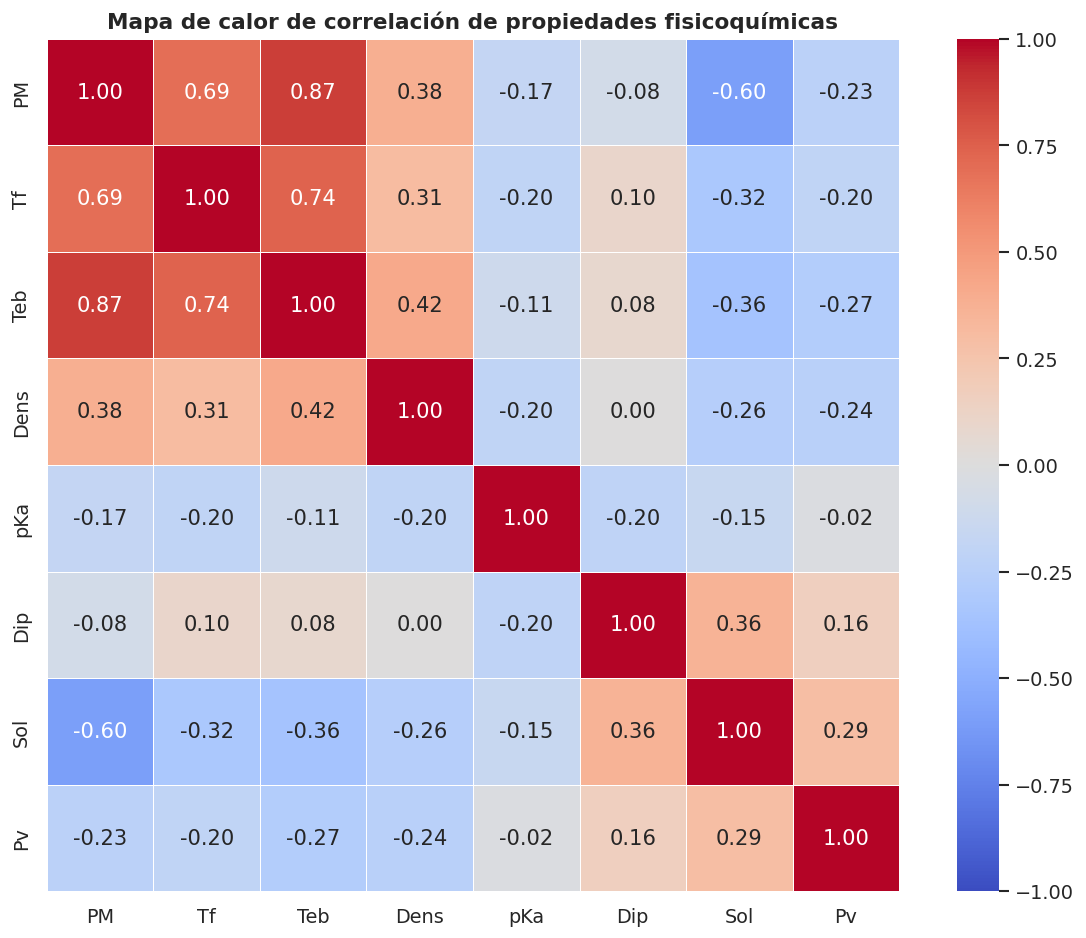

In [ ]:
# G1: Mapa de calor de correlación de propiedades fisicoquímicas

cols_prop = ["PM", "Tf", "Teb", "Dens", "pKa", "Dip", "Sol", "Pv"]

# Calcular correlaciones
corr = quim[cols_prop].corr(method="pearson", min_periods=5)

#Crear mapa de calor
plt.figure(figsize=(10, 8))

mask = corr.isna()

sns.heatmap(
    corr,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    vmin=-1,
    vmax=1,
    center=0,
    linewidths=0.5,
    mask=mask,
    square=True
)

plt.title("Mapa de calor de correlación de propiedades fisicoquímicas")
plt.tight_layout()

guardar("g01_mapa_calor_propiedades")

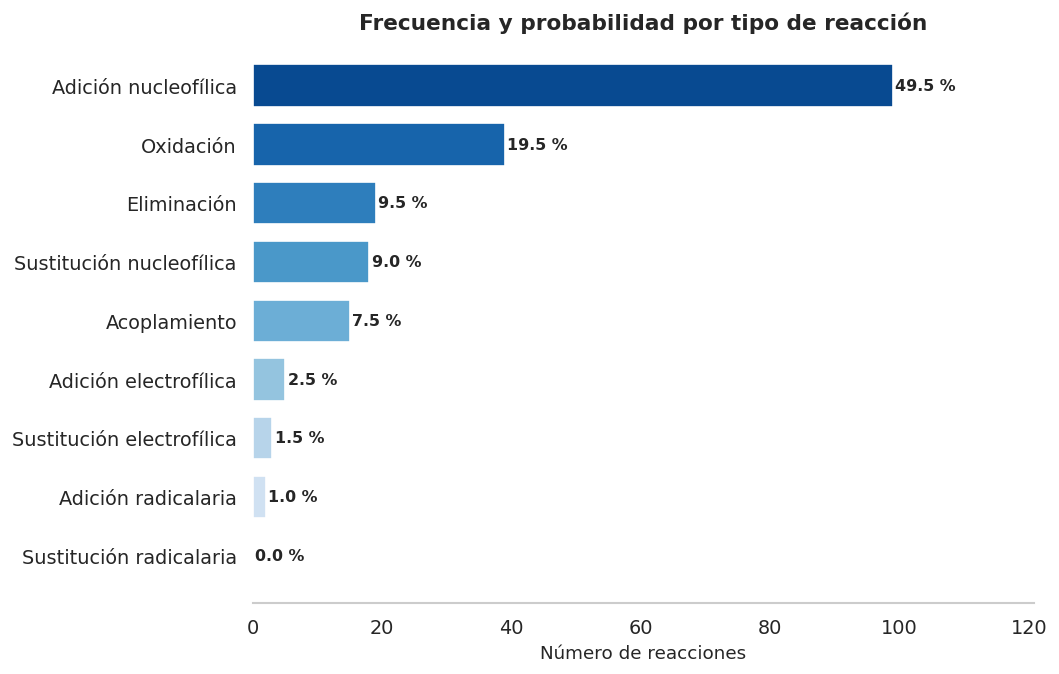

In [ ]:
# G2: Frecuencia y probabilidad por tipo de reacción

# Muestra SIEMPRE los 9 tipos (los que no aparecen en la tabla salen con 0)
orden_tipos = TIPOS_9
conteo = df["Tipo_n"].value_counts().reindex(orden_tipos, fill_value=0).sort_values(ascending=False)
prob = conteo / conteo.sum() * 100

fig, ax = plt.subplots(figsize=(9, 5.8))

colors = sns.color_palette("Blues_r", n_colors=len(conteo))

bars = ax.barh(
    conteo.index,
    conteo.values,
    color=colors,
    edgecolor="white",
    height=0.72
)

for i, (c, p) in enumerate(zip(conteo.values, prob.values)):
    ax.text(
        c + 0.4, i,
        f"{p:.1f} %",
        va="center",
        fontsize=9.5,
        fontweight="bold"
    )

ax.set_xlim(0, conteo.max() * 1.22)
ax.set_xlabel("Número de reacciones")
ax.set_title("Frecuencia y probabilidad por tipo de reacción")
ax.invert_yaxis()

# Quitar todas las cuadrículas
ax.grid(False)

sns.despine(left=True)

guardar("g02_tipo_reaccion")

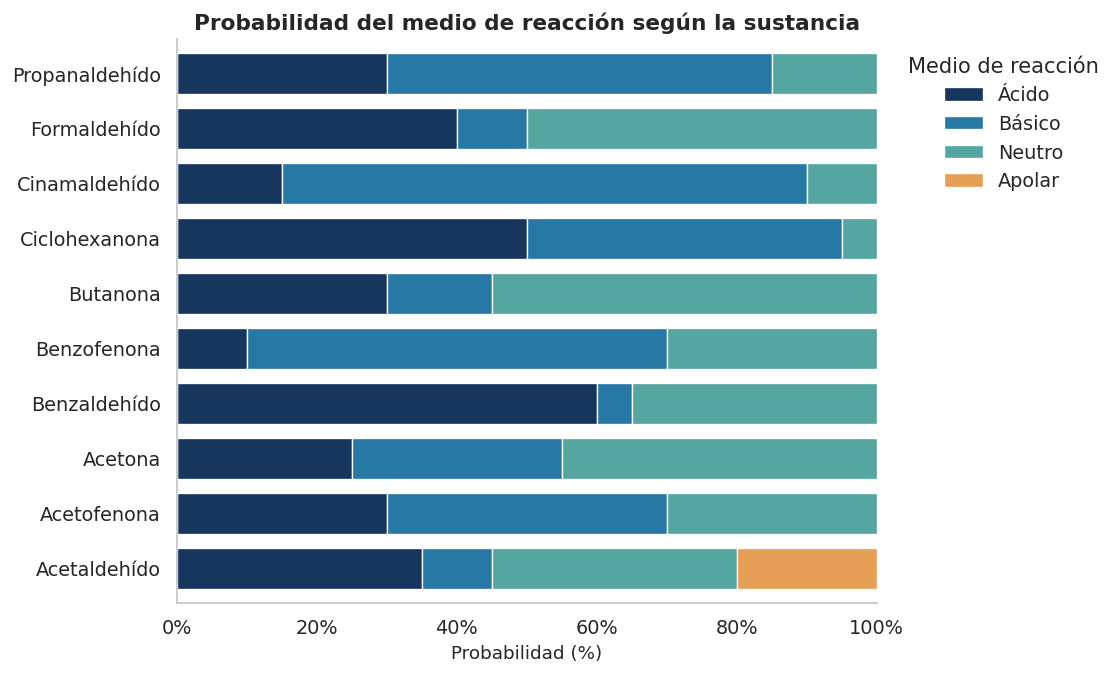

In [ ]:
# G3: Probabilidad del medio por sustancia (100 % apilado)

tab = pd.crosstab(
    df["Compuesto"],
    df["Medio_n"],
    normalize="index"
) * 100

orden_m = [
    m for m in ["Ácido", "Básico", "Neutro", "Apolar", "No especificado"]
    if m in tab.columns
]

tab = tab[orden_m].reindex(sorted(tab.index))

# Paleta de colores
PAL_MEDIO = {
    "Ácido": "#17365D",
    "Básico": "#2878A5",
    "Neutro": "#55A6A1",
    "Apolar": "#E69F56",
    "No especificado": "#A6ADB4"
}

fig, ax = plt.subplots(figsize=(9.5, 5.8))

tab.plot(
    kind="barh",
    stacked=True,
    color=[PAL_MEDIO[m] for m in orden_m],
    edgecolor="white",
    linewidth=0.8,
    width=0.75,
    ax=ax
)

ax.set_xlim(0, 100)
ax.set_xlabel("Probabilidad (%)")
ax.set_ylabel("")
ax.set_title("Probabilidad del medio de reacción según la sustancia")

ax.legend(
    title="Medio de reacción",
    bbox_to_anchor=(1.02, 1),
    loc="upper left",
    frameon=False
)

ax.xaxis.set_major_formatter(PercentFormatter(100))

# Eliminar todas las cuadrículas
ax.grid(False)

sns.despine()
plt.tight_layout()

guardar("g03_medio_por_sustancia")

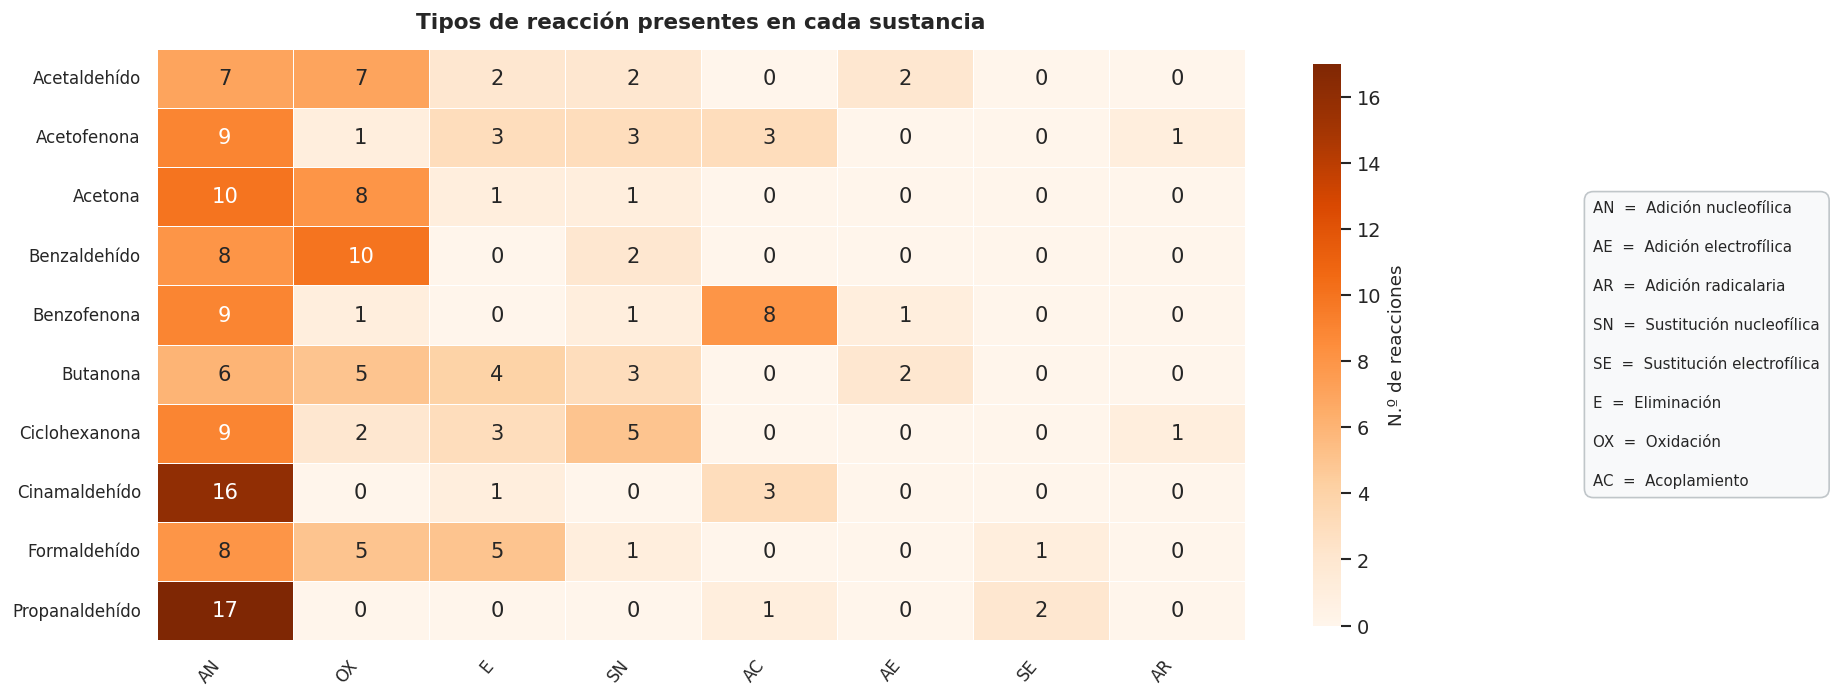

In [ ]:
# G4: Mapa de calor sustancia vs tipo de reacción
mapa = pd.crosstab(df["Compuesto"], df["Tipo_n"])
mapa = mapa[mapa.sum().sort_values(ascending=False).index]

# Abreviaturas (los 9 tipos permitidos)
ABREV = {
    "Adición nucleofílica": "AN",
    "Adición electrofílica": "AE",
    "Adición radicalaria": "AR",
    "Sustitución nucleofílica": "SN",
    "Sustitución electrofílica": "SE",
    "Sustitución radicalaria": "SR",
    "Eliminación": "E",
    "Oxidación": "OX",
    "Acoplamiento": "AC",
    "Otras": "OTR",
}

mapa_corto = mapa.rename(columns=ABREV)

fig, ax = plt.subplots(figsize=(15, 6))

sns.heatmap(
    mapa_corto,
    annot=True,
    fmt="d",
    cmap="Oranges",
    linewidths=0.6,
    linecolor="white",
    cbar_kws={"label": "N.º de reacciones", "shrink": 0.95},
    ax=ax
)

ax.set_title("Tipos de reacción presentes en cada sustancia", pad=12)
ax.set_xlabel("")
ax.set_ylabel("")

# Clave de la legibilidad
ax.set_xticklabels(ax.get_xticklabels(), rotation=50, ha="right", fontsize=10)
ax.set_yticklabels(ax.get_yticklabels(), rotation=0, fontsize=10)

# Leyenda
leyenda_texto = "\n".join([f"{v}  =  {k}" for k, v in ABREV.items() if k in mapa.columns])
props = dict(boxstyle="round,pad=0.6", facecolor="#f8f9fa", edgecolor="#bdc3c7", alpha=0.95)
ax.text(1.32, 0.5, leyenda_texto, transform=ax.transAxes,
        fontsize=9, va="center", ha="left", bbox=props, linespacing=3.00)

# Deja espacio suficiente a la derecha para la leyenda
plt.subplots_adjust(right=0.35, bottom=0.18)
guardar("g04_sustancia_vs_tipo")

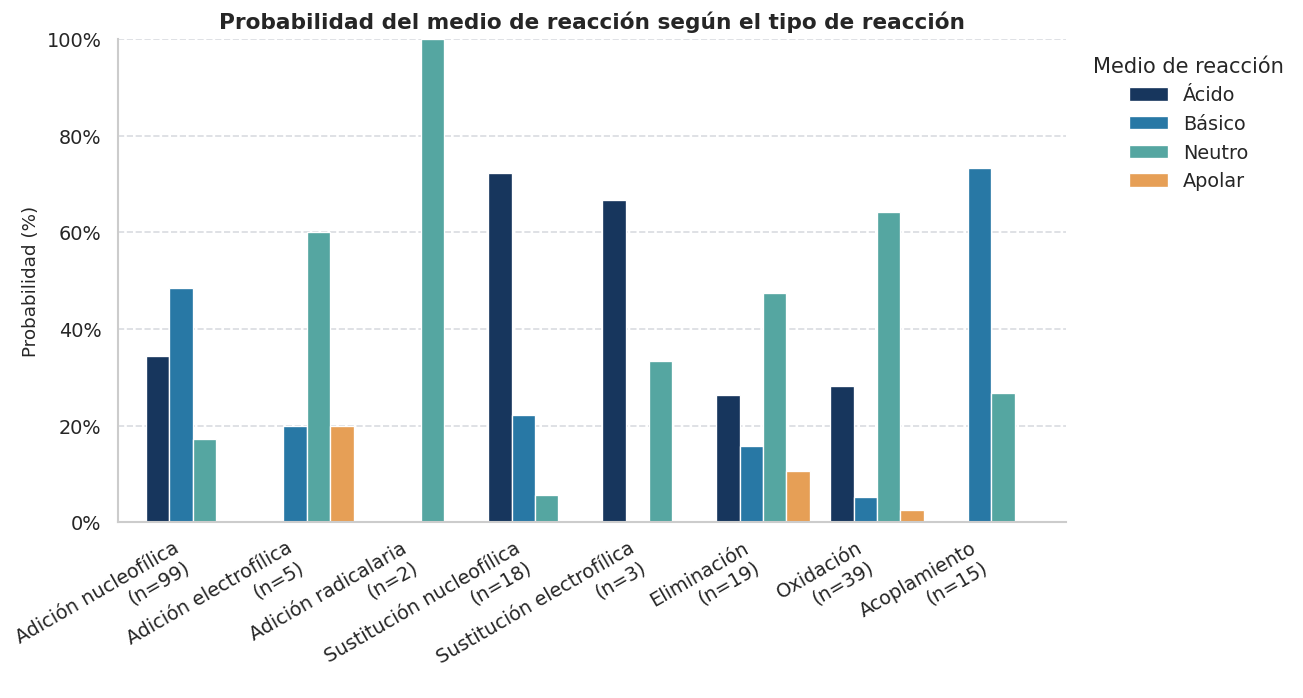

In [ ]:
# G5: Probabilidad del medio dado el tipo de reacción  (BARRAS AGRUPADAS)
# P(medio | tipo): dentro de cada tipo de reacción, qué % se hace en cada medio.
cond = (pd.crosstab(df[df.Tipo_n.isin(tipos_ok)]["Tipo_n"], df["Medio_n"], normalize="index") * 100)
cond = cond.reindex(index=tipos_ok, columns=orden_m, fill_value=0)
cond.index = [f"{t}\n(n={n_tipo[t]})" for t in cond.index]      # n = reacciones de ese tipo

fig, ax = plt.subplots(figsize=(11, 6))
cond.plot(
    kind="bar",
    ax=ax,
    color=[PAL_MEDIO[m] for m in orden_m],
    width=0.82,
    edgecolor="white",
    linewidth=0.8
)
ax.set_title("Probabilidad del medio de reacción según el tipo de reacción")
ax.set_xlabel("")
ax.set_ylabel("Probabilidad (%)")
ax.set_ylim(0, 100)
ax.yaxis.set_major_formatter(PercentFormatter(100))
plt.xticks(rotation=30, ha="right")
ax.legend(title="Medio de reacción", frameon=False, bbox_to_anchor=(1.01, 1), loc="upper left")
ax.grid(axis="y", linestyle="--", alpha=0.25, color="#667085")
ax.grid(axis="x", visible=False)
sns.despine()
guardar("g05_medio_por_tipo_barras")

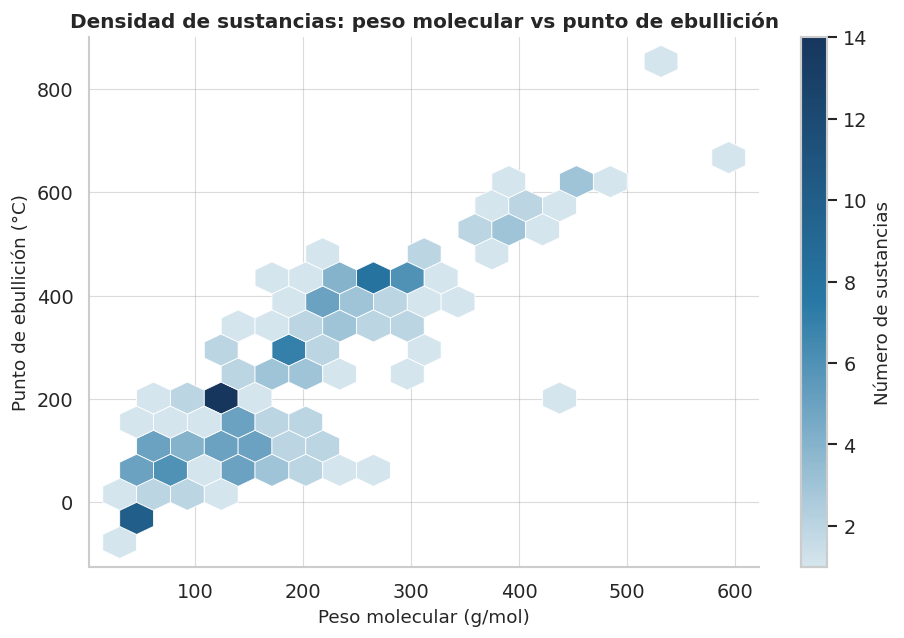

In [ ]:
# G6: Peso molecular vs punto de ebullición (Hexbin + línea de tendencia)

d = quim.dropna(subset=["PM", "Teb"])

fig, ax = plt.subplots(figsize=(8, 5.5))

# Degradado azul científico: claro a oscuro
from matplotlib.colors import LinearSegmentedColormap

azul_cientifico = LinearSegmentedColormap.from_list(
    "azul_cientifico",
    ["#D5E5ED", "#2878A5", "#17365D"]
)

# Gráfico de hexágonos
hb = ax.hexbin(
    d["PM"],
    d["Teb"],
    gridsize=18,
    cmap=azul_cientifico,
    mincnt=1,
    linewidths=0.5,
    edgecolors="white"
)

# Barra de color
cb = fig.colorbar(hb, ax=ax)
cb.set_label("Número de sustancias")


# Título y etiquetas
ax.set_title(
    "Densidad de sustancias: peso molecular vs punto de ebullición",
    fontsize=12,
    fontweight="bold"
)

ax.set_xlabel("Peso molecular (g/mol)")
ax.set_ylabel("Punto de ebullición (°C)")

# Conservar cuadrículas
ax.grid(
    True,
    linestyle="-",
    linewidth=0.7,
    alpha=0.45,
    color="#B0B0B0"
)

sns.despine()
plt.tight_layout()

guardar("g06_pm_vs_teb_hexbin")

AVISO G7: sin presión de vapor en el Excel para: ['Propanaldehído']


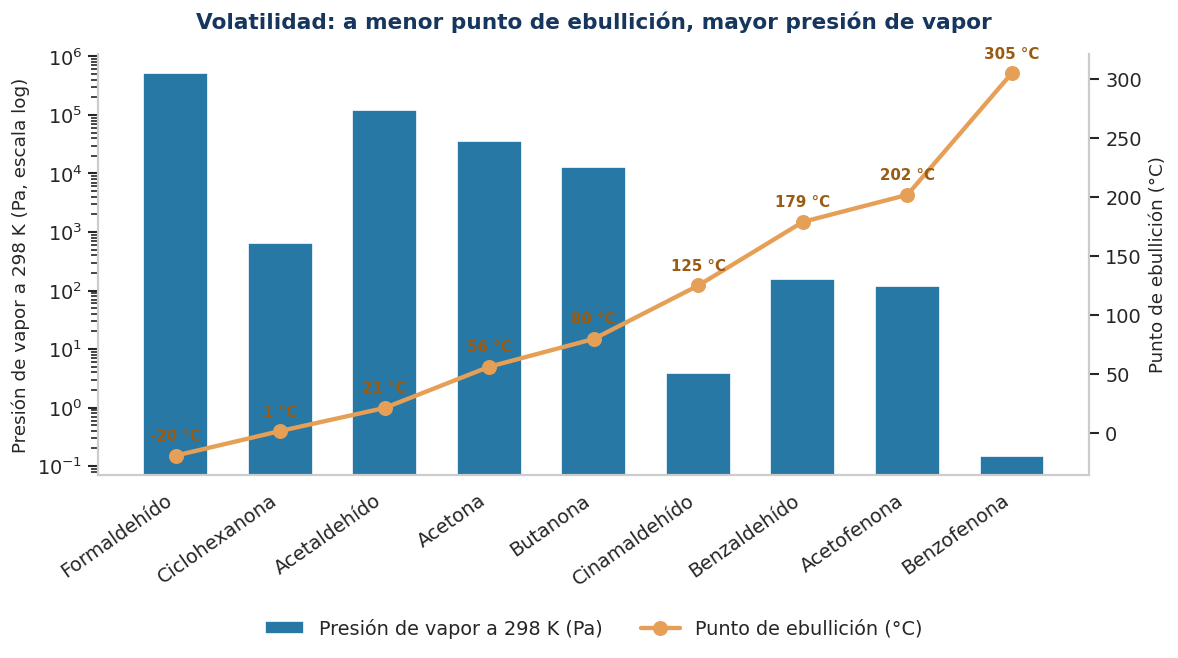

In [ ]:
# G7: Volatilidad: presión de vapor (barras) y punto de ebullición (línea)
vol = (df[df.Rol == "Reacción"]
       .groupby("Compuesto")[["Teb_S", "Pv_S"]].median()
       .sort_values("Teb_S"))
faltan_pv = vol[vol["Pv_S"].isna()].index.tolist()
if faltan_pv:
    print("AVISO G7: sin presión de vapor en el Excel para:", faltan_pv)
vol = vol.dropna(subset=["Teb_S", "Pv_S"])

fig, ax = plt.subplots(figsize=(10, 6))
x = np.arange(len(vol))

ax.bar(x, vol["Pv_S"], color="#2878A5", width=0.62, edgecolor="white", label="Presión de vapor a 298 K (Pa)")
ax.set_yscale("log")
ax.set_ylabel("Presión de vapor a 298 K (Pa, escala log)")
ax.set_xticks(x)
ax.set_xticklabels(vol.index, rotation=35, ha="right")
ax.grid(False)

ax2 = ax.twinx()
ax2.plot(x, vol["Teb_S"], color="#E69F56", marker="o", markersize=8, linewidth=2.6, label="Punto de ebullición (°C)")
for xi, v in zip(x, vol["Teb_S"]):
    ax2.annotate(f"{v:.0f} °C", (xi, v), textcoords="offset points", xytext=(0, 9),
                 ha="center", fontsize=9, color="#9A5B12", fontweight="bold")
ax2.set_ylabel("Punto de ebullición (°C)")
ax2.grid(False)

ax.set_title("Volatilidad: a menor punto de ebullición, mayor presión de vapor",
             fontsize=13, fontweight="bold", color="#17365D", pad=15)

h1, l1 = ax.get_legend_handles_labels()
h2, l2 = ax2.get_legend_handles_labels()
ax.legend(h1 + h2, l1 + l2, loc="upper center", bbox_to_anchor=(0.5, -0.30), frameon=False, ncol=2)
sns.despine(right=False)
guardar("g07_volatilidad_pv_teb")

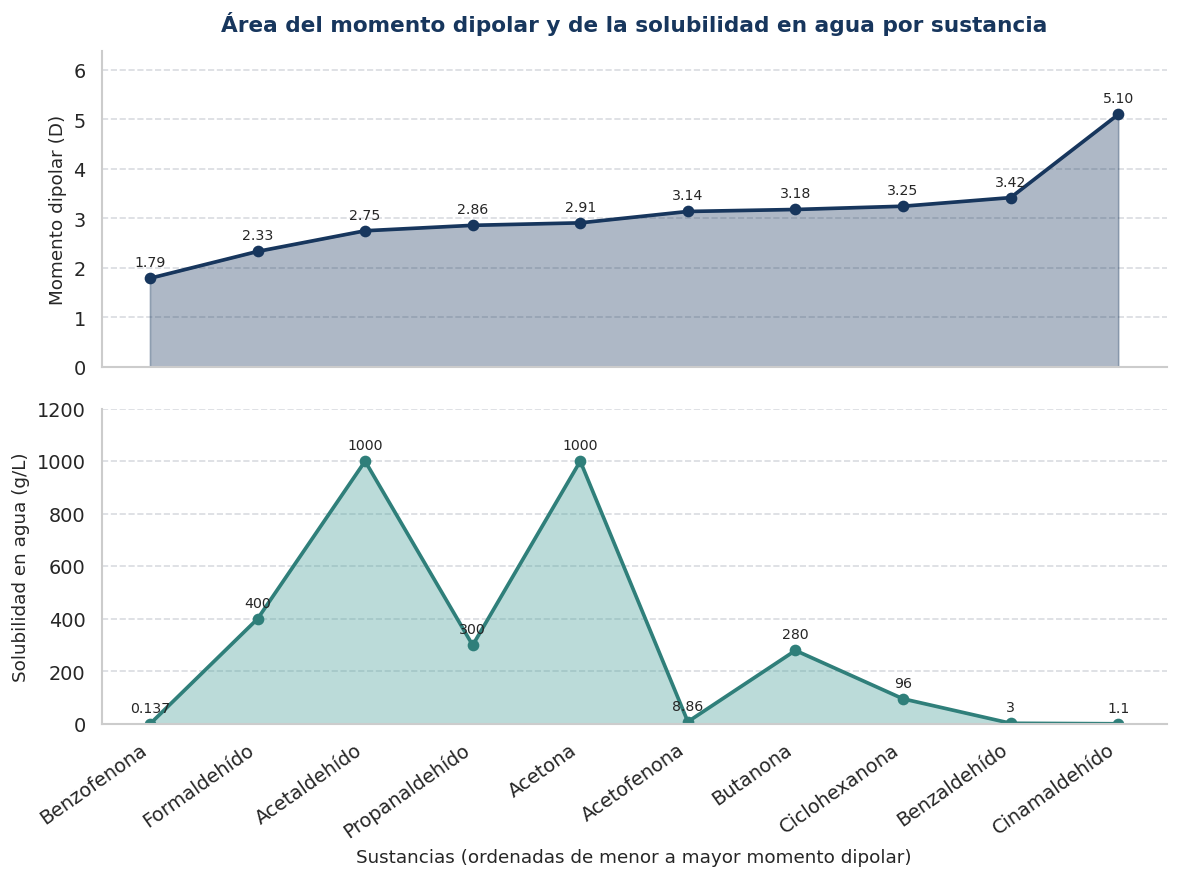

In [ ]:
# G8: Áreas de momento dipolar y de solubilidad en agua (por sustancia)
prop = (df[df.Rol == "Reacción"]
        .groupby("Compuesto")[["Dip_S", "Sol_S"]].median()
        .sort_values("Dip_S"))                       # sustancias ordenadas de menor a mayor dipolo

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(10, 7.5), sharex=True)
x = np.arange(len(prop))

# Área 1: momento dipolar
d1 = prop["Dip_S"].dropna()
x1 = [list(prop.index).index(c) for c in d1.index]
ax1.fill_between(x1, d1.values, color="#17365D", alpha=0.35)
ax1.plot(x1, d1.values, color="#17365D", marker="o", linewidth=2.2)
for xi, v in zip(x1, d1.values):
    ax1.annotate(f"{v:.2f}", (xi, v), textcoords="offset points", xytext=(0, 7), ha="center", fontsize=8.5)
ax1.set_ylabel("Momento dipolar (D)")
ax1.set_ylim(0, d1.max() * 1.25)
ax1.set_title("Área del momento dipolar y de la solubilidad en agua por sustancia",
              fontsize=13, fontweight="bold", color="#17365D", pad=12)

# Área 2: solubilidad en agua
d2 = prop["Sol_S"].dropna()
x2 = [list(prop.index).index(c) for c in d2.index]
ax2.fill_between(x2, d2.values, color="#55A6A1", alpha=0.40)
ax2.plot(x2, d2.values, color="#2F7F7A", marker="o", linewidth=2.2)
for xi, v in zip(x2, d2.values):
    ax2.annotate(f"{v:g}", (xi, v), textcoords="offset points", xytext=(0, 7), ha="center", fontsize=8.5)
ax2.set_ylabel("Solubilidad en agua (g/L)")
ax2.set_ylim(0, d2.max() * 1.2)

ax2.set_xticks(x)
ax2.set_xticklabels(prop.index, rotation=35, ha="right")
ax2.set_xlabel("Sustancias (ordenadas de menor a mayor momento dipolar)")
for a in (ax1, ax2):
    a.grid(axis="y", linestyle="--", alpha=0.25, color="#667085")
    a.grid(axis="x", visible=False)
sns.despine()
guardar("g08_areas_dipolo_solubilidad")

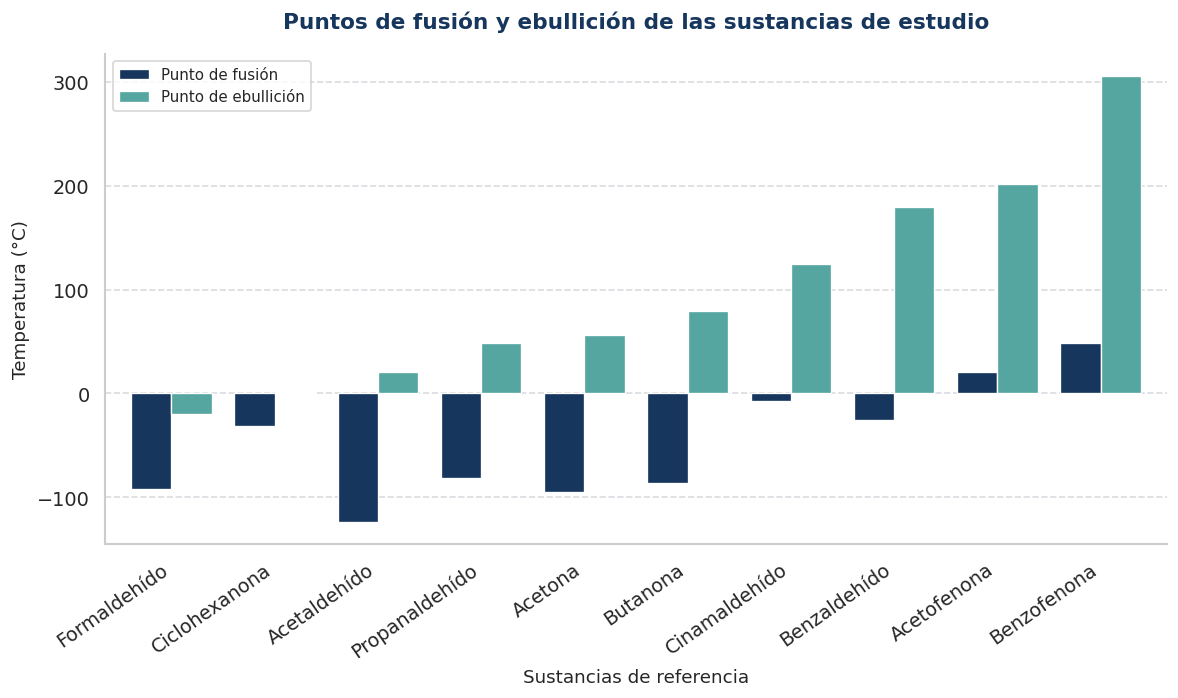

In [ ]:
# G9: Tf y Teb de las sustancias de referencia

ref = (df[df.Rol == "Reacción"]
       .groupby("Compuesto")[["Tf_S", "Teb_S"]]
       .median()
       .sort_values("Teb_S"))

ref = ref.rename(columns={
    "Tf_S": "Punto de fusión",
    "Teb_S": "Punto de ebullición"
})

fig, ax = plt.subplots(figsize=(10, 6))

# Barras agrupadas con paleta científica
ref.plot(
    kind="bar",
    ax=ax,
    color=["#17365D", "#55A6A1"],
    width=0.78,
    edgecolor="white",
    linewidth=0.8
)

# Título y etiquetas
ax.set_title(
    "Puntos de fusión y ebullición de las sustancias de estudio",
    fontsize=13,
    fontweight="bold",
    color="#17365D",
    pad=15
)

ax.set_ylabel("Temperatura (°C)")
ax.set_xlabel("Sustancias de referencia")

plt.xticks(rotation=35, ha="right")

ax.legend(
    frameon=True,
    loc="upper left",
    fontsize=9
)

ax.grid(
    axis="y",
    linestyle="--",
    alpha=0.25,
    color="#667085"
)
ax.grid(axis="x", visible=False)
sns.despine()
plt.tight_layout()

guardar("g09_tf_teb_referencia")

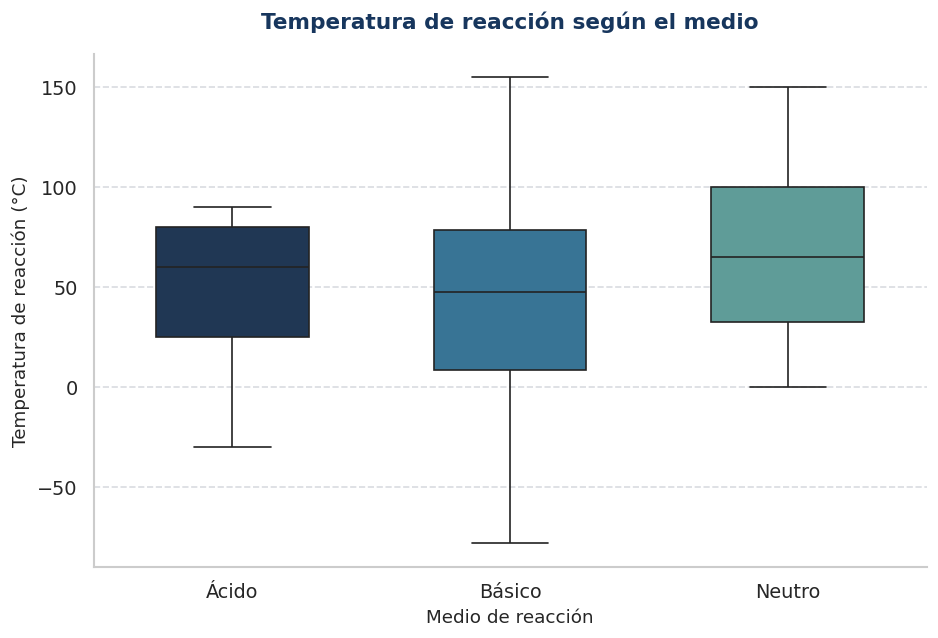

In [ ]:
# G10: Temperatura de reacción por medio (Boxplot)

dt = df[
    df.T_rx.between(-80, 350) &
    df.Medio_n.isin(["Ácido", "Básico", "Neutro"])
]

fig, ax = plt.subplots(figsize=(8, 5.5))

# Colores de la paleta científica
PAL_TEMP = {
    "Ácido": "#17365D",
    "Básico": "#2878A5",
    "Neutro": "#55A6A1"
}

sns.boxplot(
    data=dt,
    x="Medio_n",
    y="T_rx",
    hue="Medio_n",
    palette=PAL_TEMP,
    legend=False,
    showmeans=False,
    showfliers=False,
    meanprops=dict(
        marker="D",
        markerfacecolor="white",
        markeredgecolor="#17365D",
        markersize=7
    ),
    order=["Ácido", "Básico", "Neutro"],
    width=0.55,
    ax=ax
)

# Título y etiquetas
ax.set_title(
    "Temperatura de reacción según el medio",
    fontsize=13,
    fontweight="bold",
    color="#17365D",
    pad=15
)

ax.set_xlabel("Medio de reacción")
ax.set_ylabel("Temperatura de reacción (°C)")

ax.grid(
    axis="y",
    linestyle="--",
    alpha=0.25,
    color="#667085"
)

sns.despine()
plt.tight_layout()

guardar("g10_temp_por_medio")

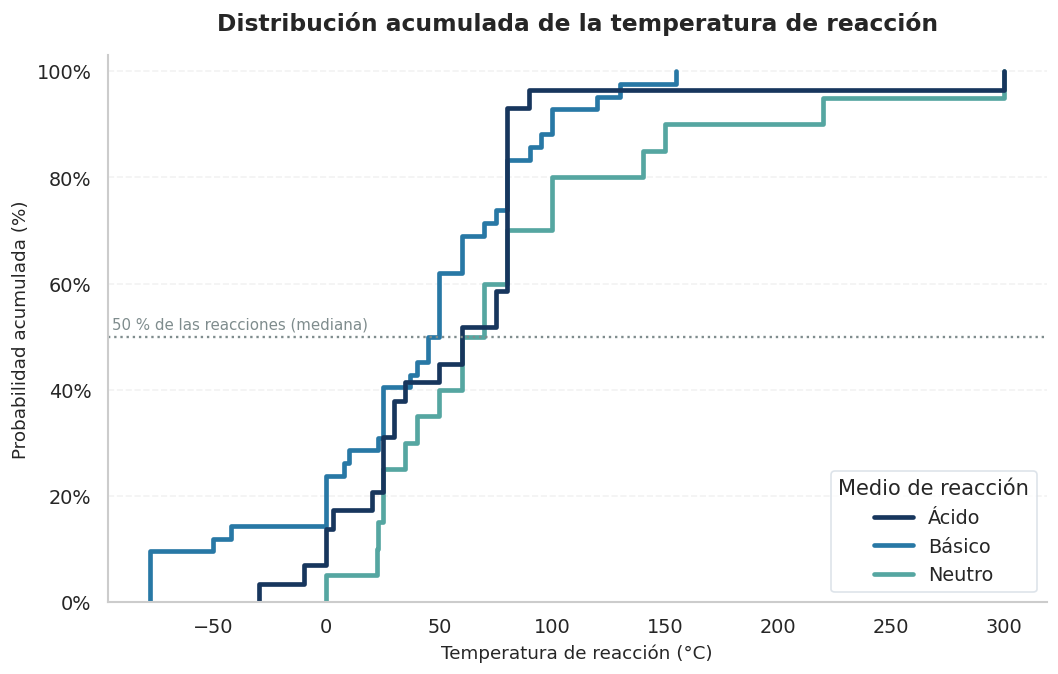

In [ ]:
# G11: ECDF de temperatura de reacción por medio
# Cómo leerla: para una temperatura t del eje X, la curva dice qué % de las reacciones
# de ese medio se hacen a t °C o MENOS. Donde la curva cruza el 50 % está la mediana.

fig, ax = plt.subplots(figsize=(9, 5.8))

# Paleta profesional
pal_ecdf = {
    "Ácido": "#17365D",
    "Básico": "#2878A5",
    "Neutro": "#55A6A1"
}

sns.ecdfplot(
    data=dt,
    x="T_rx",
    hue="Medio_n",
    hue_order=["Ácido", "Básico", "Neutro"],
    palette=pal_ecdf,
    linewidth=2.8,
    ax=ax
)

# Línea de la mediana (50 %) para poder explicarla
ax.axhline(0.5, color="#7f8c8d", linestyle=":", linewidth=1.4)
ax.text(ax.get_xlim()[0] + 2, 0.515, "50 % de las reacciones (mediana)", color="#7f8c8d", fontsize=9)

# Ejes y formato
ax.set_title(
    "Distribución acumulada de la temperatura de reacción",
    fontsize=14,
    fontweight="bold",
    pad=15
)

ax.set_xlabel("Temperatura de reacción (°C)", fontsize=11)
ax.set_ylabel("Probabilidad acumulada (%)", fontsize=11)

ax.yaxis.set_major_formatter(
    PercentFormatter(1)
)

ax.set_ylim(0, 1.03)

# Cuadrícula y leyenda
ax.grid(axis="y", linestyle="--", alpha=0.25)
ax.grid(axis="x", visible=False)

sns.move_legend(
    ax, "lower right",
    title="Medio de reacción",
    frameon=True,
    facecolor="white",
    edgecolor="#D5DDE5"
)

sns.despine()
plt.tight_layout()

guardar("g11_ecdf_temperatura")

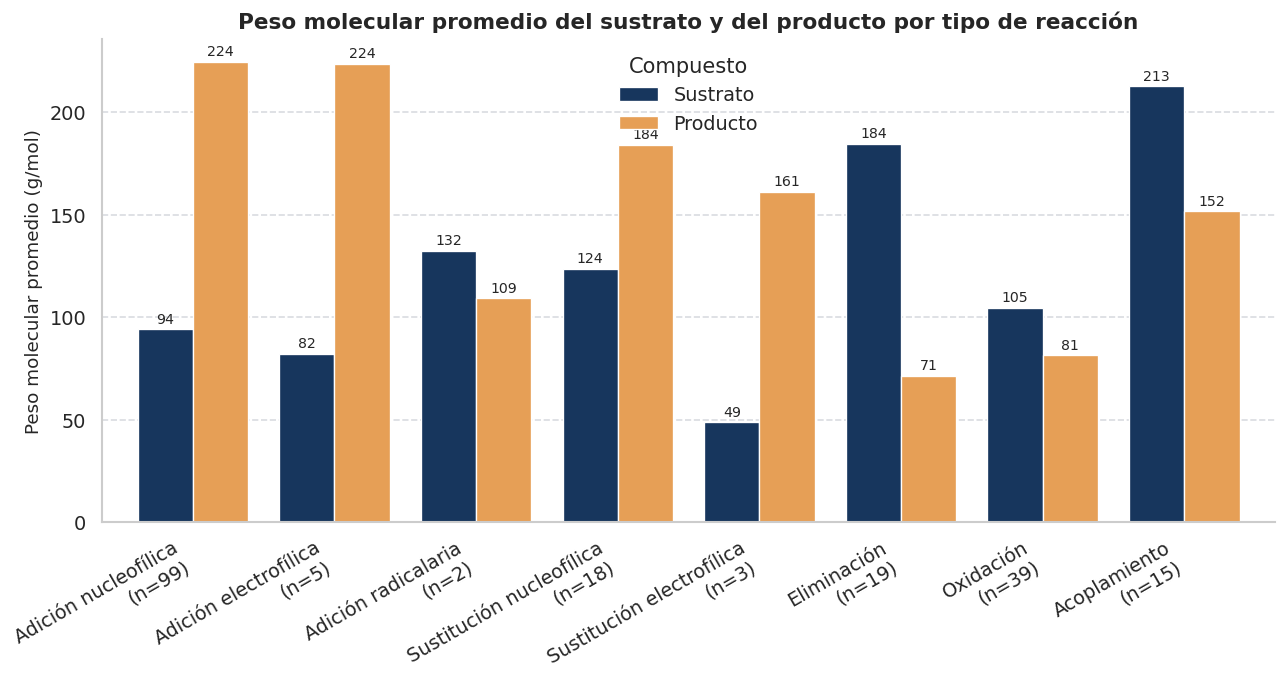

In [ ]:
# G12: Peso molecular del sustrato y del producto por tipo de reacción
# (sin restas: se comparan los dos pesos moleculares, siempre positivos)
pm = (df[df.Tipo_n.isin(tipos_ok)]
      .groupby("Tipo_n")[["PM_S", "PM_P"]].mean()
      .reindex(tipos_ok))
pm.index = [f"{t}\n(n={n_tipo[t]})" for t in pm.index]
pm = pm.rename(columns={"PM_S": "Sustrato", "PM_P": "Producto"})

fig, ax = plt.subplots(figsize=(11, 6))
pm.plot(kind="bar", ax=ax, color=["#17365D", "#E69F56"], width=0.78, edgecolor="white", linewidth=0.8)
for cont in ax.containers:
    ax.bar_label(cont, fmt="%.0f", fontsize=8.5, padding=2)
ax.set_title("Peso molecular promedio del sustrato y del producto por tipo de reacción")
ax.set_xlabel("")
ax.set_ylabel("Peso molecular promedio (g/mol)")
plt.xticks(rotation=30, ha="right")
ax.legend(title="Compuesto", frameon=False)
ax.grid(axis="y", linestyle="--", alpha=0.25, color="#667085")
ax.grid(axis="x", visible=False)
sns.despine()
guardar("g12_pm_sustrato_producto_por_tipo")

In [ ]:
#Exportar
df.drop(columns=["ref_S", "ref_P"], errors="ignore").to_csv(
    "tabla_limpia.csv", index=False, encoding="utf-8-sig")
quim.to_csv("sustancias_unicas.csv", index=False, encoding="utf-8-sig")

if EN_COLAB:
    import shutil
    shutil.make_archive("figuras", "zip", "figuras")
    files.download("figuras.zip")
    files.download("tabla_limpia.csv")
    files.download("sustancias_unicas.csv")

print("\n Listo. Figuras en ./figuras/ y datos limpios exportados.")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>


 Listo. Figuras en ./figuras/ y datos limpios exportados.
